# cnn

In [1]:
import tensorflow as tf

I0000 00:00:1792312092.753986   36521 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792312093.194481   36521 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792312095.957487   36521 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
tf.random.set_seed(0)

In [3]:
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/taj_mahal.jpg'
image_path = tf.keras.utils.get_file("taj_mahal.jpg", url)

138206/138206 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
def read_image(image_path, target_size=None):
    image = tf.keras.preprocessing.image.load_img(image_path,
                target_size=target_size)
    image = tf.keras.preprocessing.image.img_to_array(image)
    image = image.astype(np.uint8)
    return image

image = read_image(image_path)

In [5]:
image.shape

(468, 468, 3)

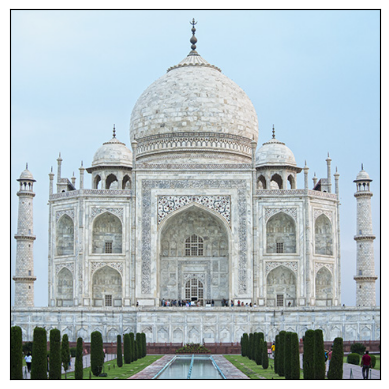

In [6]:
plt.imshow(image)
plt.xticks([])
plt.yticks([])
plt.show()

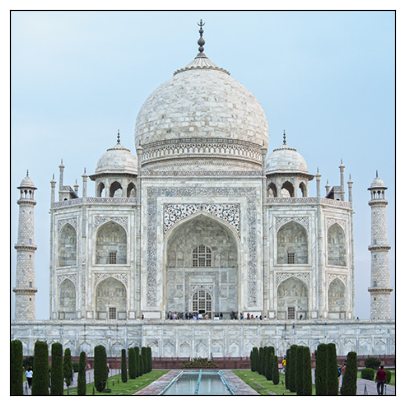

In [ ]:
identity_kernel = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
])

## filtro de identidad. deja la imagen igual de lo que estaba


img = cv2.filter2D(image, -1, identity_kernel)

fig, ax = plt.subplots(1, figsize=(5, 5))
ax.set_xticks([])
ax.set_yticks([])
plt.imshow(img);

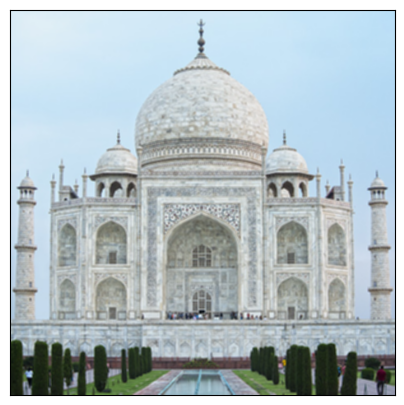

In [ ]:
box_blur_filter = (1/9) * np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

# hace promedio de los pizeles de la imagen haciendoq ue se difuminen los bordes y se vea con mas brillo los detalles

img = cv2.filter2D(image, -1, box_blur_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
ax.set_xticks([])
ax.set_yticks([])
plt.imshow(img);

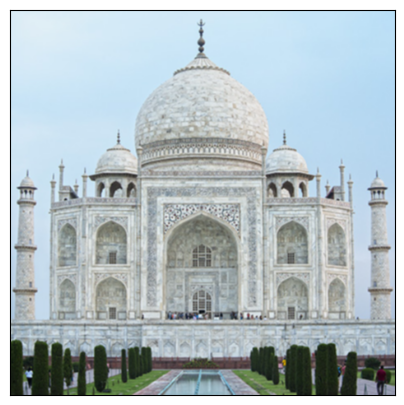

In [ ]:
gaussian_blur_filter = (1/16) * np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

## no elimina tantos detalles y puede lelgar a mejorrar la imagen


img = cv2.filter2D(image, -1, gaussian_blur_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
ax.set_xticks([])
ax.set_yticks([])

plt.imshow(img);

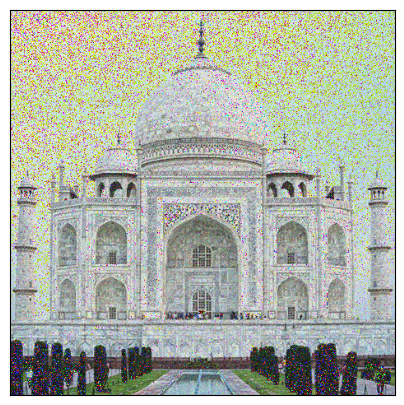

In [ ]:
sigma = 20
n, m, k = image.shape
img_noise = image + sigma*np.random.randn(n, m, k)
fig, ax = plt.subplots(1, figsize=(5, 5))
ax.set_xticks([])
ax.set_yticks([])
# si añadiesemos ruido por ejemplo a la imagen nosotros podriamos ver como hacen los filtros para quitarle el ruido y mejorar la imagen

plt.imshow(img_noise.astype(np.uint8));

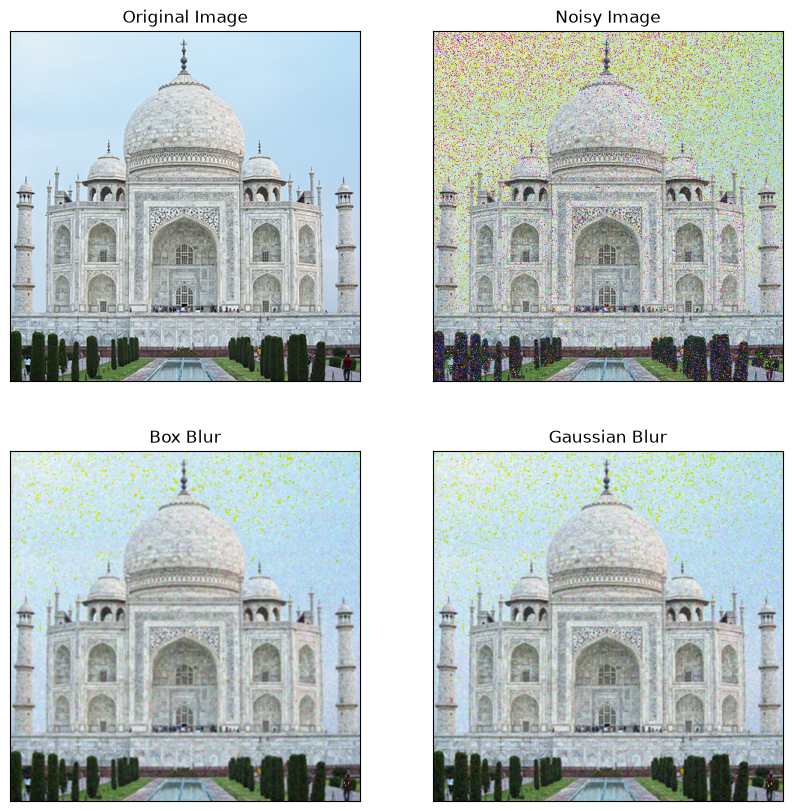

In [11]:
img1 = cv2.filter2D(img_noise, -1, gaussian_blur_filter)

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

for i in range(ax.shape[0]):
    for j in range(ax.shape[1]):
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])
        
ax[0, 0].set_title('Original Image')
ax[0, 0].imshow(image.astype(np.uint8));

ax[0, 1].set_title('Noisy Image')
ax[0, 1].imshow(img_noise.astype(np.uint8));

ax[1, 0].set_title('Box Blur')
ax[1, 0].imshow(cv2.filter2D(img_noise, -1, box_blur_filter).astype(np.uint8));

ax[1, 1].set_title('Gaussian Blur')
ax[1, 1].imshow(cv2.filter2D(img_noise, -1, gaussian_blur_filter).astype(np.uint8));

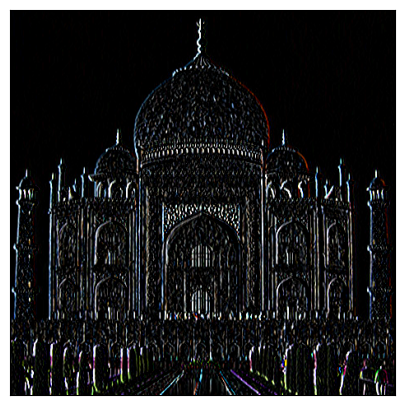

In [ ]:
edge_detection_filter = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# con este podemos ver los detectores de limites. ahroa detectamos las ejees verticales

img = cv2.filter2D(image, -1, edge_detection_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
plt.xticks([])
plt.yticks([])

plt.imshow(img);

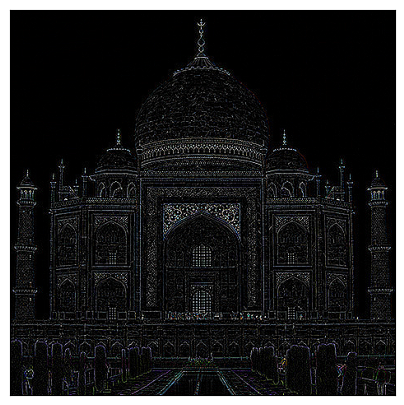

In [ ]:
edge_detection_filter = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

# detectamos los bordes en las direcciones puestas en el array

img = cv2.filter2D(image, -1, edge_detection_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
plt.xticks([])
plt.yticks([])

plt.imshow(img);

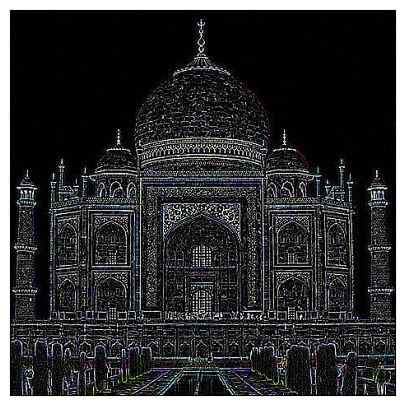

In [ ]:
edge_detection_filter = np.array([
    [1, 1, 1],
    [1, -8, 1],
    [1, 1, 1]
])

# o podemos detectar los bordes en todas las direcciones

img = cv2.filter2D(image, -1, edge_detection_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
plt.xticks([])
plt.yticks([])

plt.imshow(img);

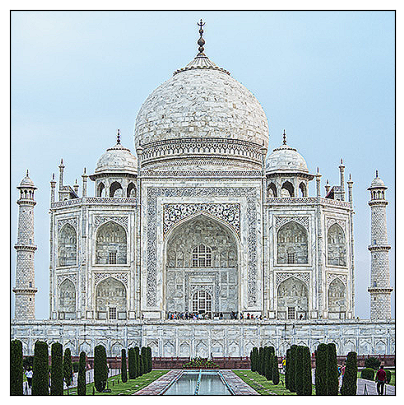

In [ ]:
sharpen_filter = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# con este filtro es restarles los bordes a la imagen oribginal y resalta el interior de la imagen q esta dentro de los bordes

img = cv2.filter2D(image, -1, sharpen_filter)

fig, ax = plt.subplots(1, figsize=(5, 5))
plt.xticks([])
plt.yticks([])
plt.imshow(img);

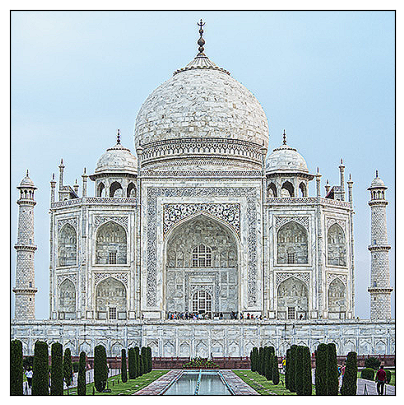

In [ ]:
kernel = np.ones((1, 1), np.uint8)
dilation = cv2.dilate(img, kernel, iterations=1)

# este es otro tipo de filtro por ejemplo. para dilatar la iamgen


fig, ax = plt.subplots(1, figsize=(5, 5))
plt.xticks([])
plt.yticks([])
plt.imshow(dilation)

In [ ]:
import pathlib
import os
import tensorflow as tf
dataset_url = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# Check the directory structure
contents = os.listdir(data_dir)
if 'flower_photos' in contents and len(contents) == 1:
    # We're in Colab - need to go one level deeper
    data_dir = os.path.join(data_dir, 'flower_photos')
    data_dir = pathlib.Path(data_dir)

# At this point, data_dir should directly contain the flower categories
print(os.listdir(data_dir))  # Should now show 'roses', 'daisy', etc. in both environments

# para este ejercicio nos guardamos un dataset con muchas flores distintas

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
['LICENSE.txt', 'sunflowers', 'dandelion', 'roses', 'daisy', 'tulips']


In [18]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


In [19]:
roses = list(data_dir.glob('roses/*'))
sunflowers = list(data_dir.glob('sunflowers/*'))

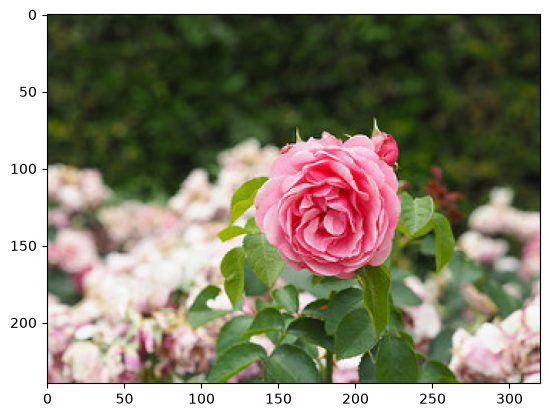

In [ ]:
im = read_image(str(roses[np.random.randint(0, len(roses))]))
plt.imshow(im); # vemos rosas

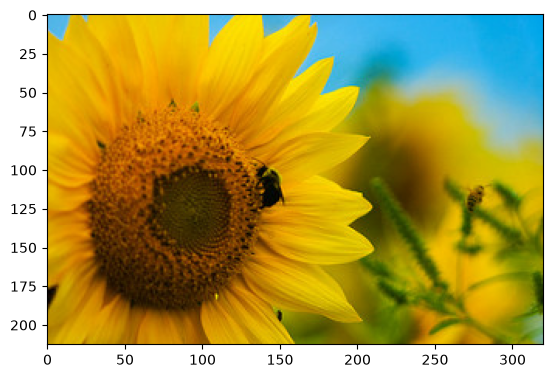

In [ ]:
im = read_image(str(sunflowers[np.random.randint(0, len(sunflowers))]))
plt.imshow(im); # vemos girasoles

In [ ]:
## vamos a crear un modelo para distinguir los distintos tipos de flores que hya.

# con esta funcion de keras es crear un dataset dede el directorio. lo q va  ahacer es recorrer el directorio y va a irlo guardando.
# uno pal tringin y otro para el validation

image_size = (96,96)
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,  # 80%  train, 20% validation
  subset='training',  # 'training' o 'validation', only  with 'validation_split'
  seed=1,
  image_size=image_size,  # Dimension (img_height, img_width) for rescaling
  batch_size=64
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


E0000 00:00:1792313506.142980   36521 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1792313506.144102   38302 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1792313506.171674   36521 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/jerry/anacon

In [23]:
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset='validation',
  seed=1,
  image_size=image_size,
  batch_size=64)


Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [24]:
class_names_list = train_ds.class_names
class_names_list

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

In [25]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

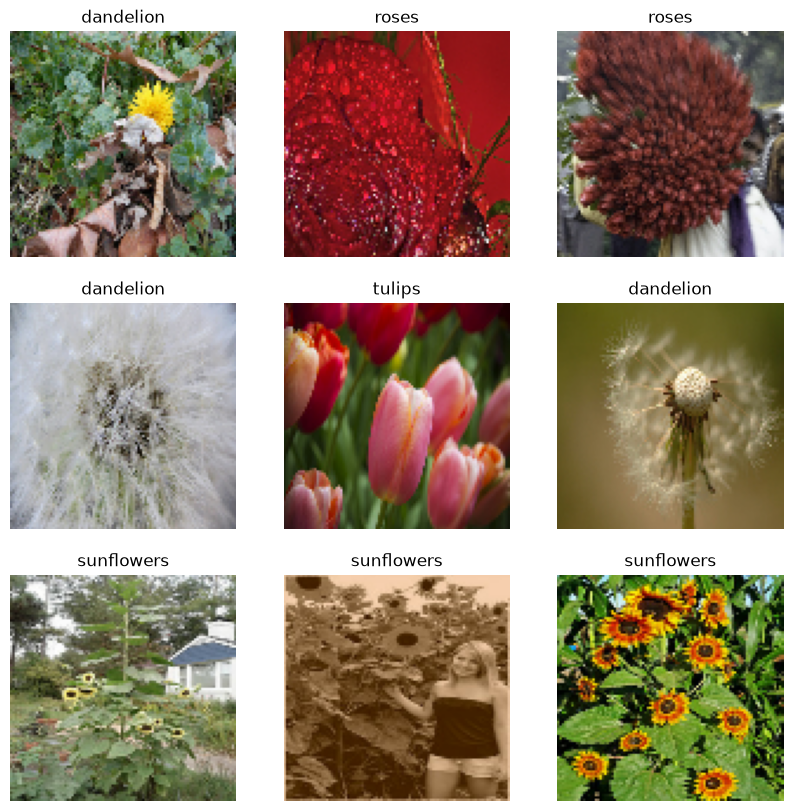

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names_list[labels[i]])
        plt.axis("off")

# vemos ejemplos del dataset

In [27]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)
    print(labels_batch.shape)
    break

(64, 96, 96, 3)
(64,)


In [28]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## vamos a hacer la primera red convuncional 

In [ ]:
inputs = tf.keras.Input(shape=image_size + (3, ), name='input')
reescaling = layers.Rescaling(1. / 255)(inputs)

# vamos a crear un ejemplo con solo 2 capas. una red convulocional y un pulling y otra capa igual.

# 4 filtros con tamaño de 3. la convulocion sera de 3x3. el pulling de 2x2 

# Conv Layer 1
conv_1 = layers.Conv2D(4, 3, padding='valid', activation='relu',
                       name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_1')(conv_1)

# Conv Layer 2
conv_2 = layers.Conv2D(4, 3, padding='valid', activation='relu',
                       name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_2')(conv_2)


# Fully-connected
# Flattening
flat = layers.Flatten(name='flatten')(pool_2)
dense = layers.Dense(64, activation='relu', name='dense')(flat)
outputs = layers.Dense(5, activation='softmax', name='output')(dense) # como tenemos 5 tipos de flores distintas, serán 5 nodos finales 1 para cada tipo

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_example')

In [30]:
model.summary()

Model: "cnn_example"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 94, 94, 4)      │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 47, 47, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 45, 45, 4)      │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 22, 22, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1936)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       123,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,553 (486.54 KB)

 Trainable params: 124,553 (486.54 KB)

 Non-trainable params: 0 (0.00 B)

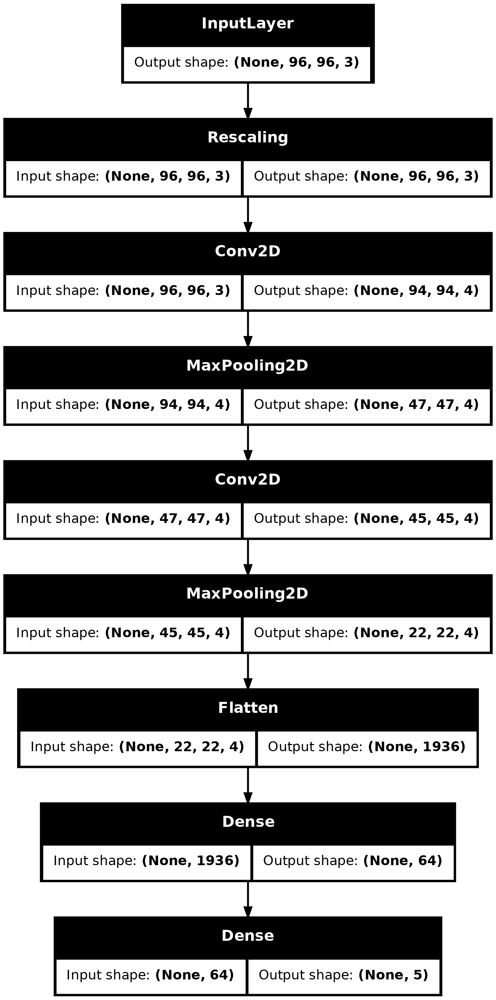

In [31]:
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes=True)

In [32]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [33]:
epochs = 8
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
)

Epoch 1/8


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step - accuracy: 0.2653 - loss: 1.6075 - val_accuracy: 0.3774 - val_loss: 1.5142
Epoch 2/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.4084 - loss: 1.4350 - val_accuracy: 0.5041 - val_loss: 1.2911
Epoch 3/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.4908 - loss: 1.2268 - val_accuracy: 0.4782 - val_loss: 1.2087
Epoch 4/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.5565 - loss: 1.0944 - val_accuracy: 0.5341 - val_loss: 1.1070
Epoch 5/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.5794 - loss: 1.0435 - val_accuracy: 0.5518 - val_loss: 1.1657
Epoch 6/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.6056 - loss: 1.0026 - val_accuracy: 0.5681 - val_loss: 1.0778
Epoch 7/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.6291 - loss: 0.9576 - val_accuracy: 0.5708 - val_loss: 1.0662
Epoch 8/8
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.6522 - loss: 0.9125 - val_accuracy: 0.5681 - val_loss: 1.1114


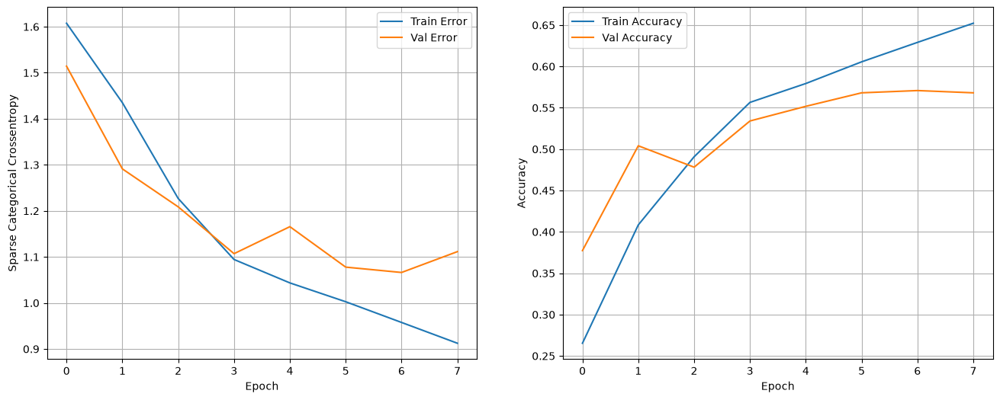

In [34]:
import pandas as pd
def show_loss_accuracy_evolution(history):
    
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Sparse Categorical Crossentropy')
    ax1.plot(hist['epoch'], hist['loss'], label='Train Error')
    ax1.plot(hist['epoch'], hist['val_loss'], label = 'Val Error')
    ax1.grid()
    ax1.legend()

    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.plot(hist['epoch'], hist['accuracy'], label='Train Accuracy')
    ax2.plot(hist['epoch'], hist['val_accuracy'], label = 'Val Accuracy')
    ax2.grid()
    ax2.legend()

    plt.show()

show_loss_accuracy_evolution(history)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step 


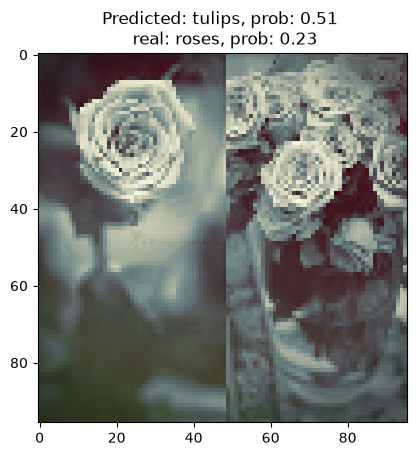

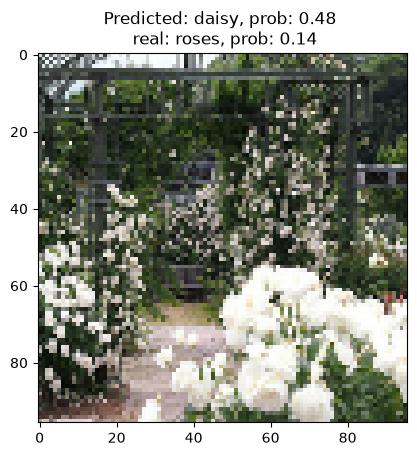

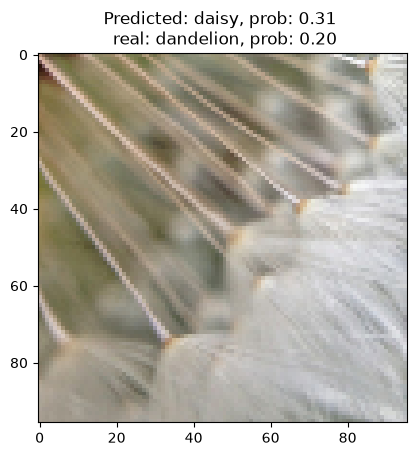

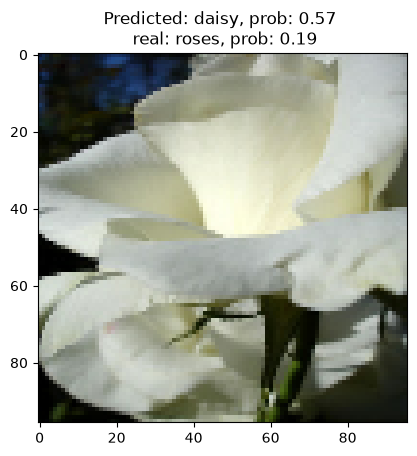

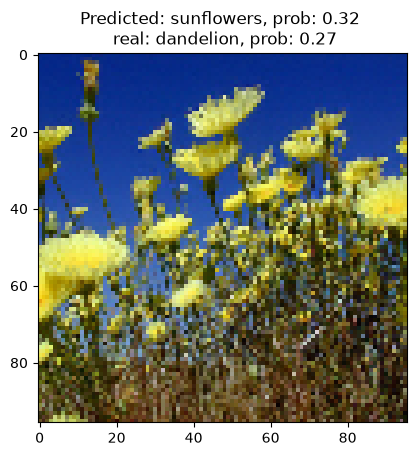

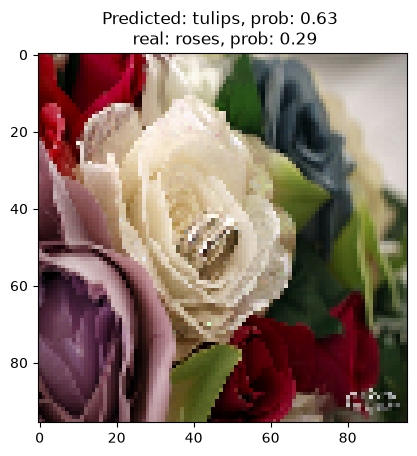

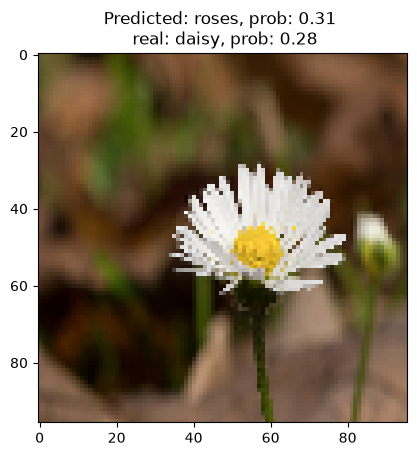

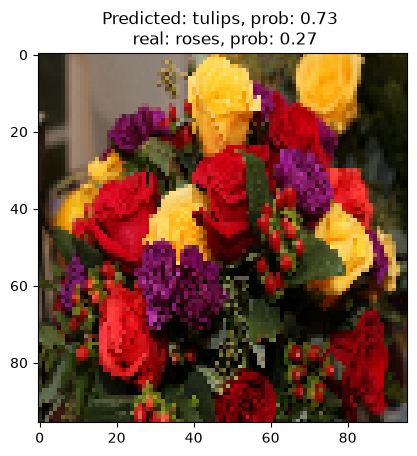

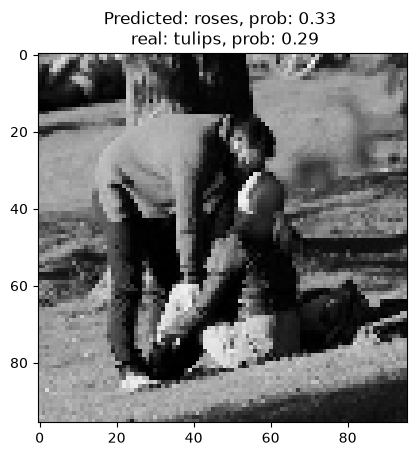

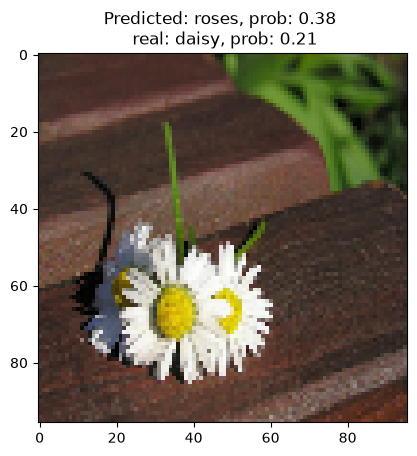

In [ ]:
def show_errors(val_ds, model, class_names_list, n_images=10):
    """Display the first n_images misclassified samples."""
    n_plots = 0
    for images, labels in val_ds:
        pred_probs = model.predict(images)
        preds = pred_probs.argmax(axis=-1)
        bad_pred_inds = np.where(preds != labels)[0]
        for ind in list(bad_pred_inds):
            n_plots += 1
            real_label = labels[ind].numpy()
            real_class = class_names_list[real_label]
            pred_class = class_names_list[preds[ind]]
            prob_pred = pred_probs[ind].max()
            prob_real = pred_probs[ind][real_label]
            plt.imshow(images[ind].numpy().astype("uint8"))
            plt.title(
                'Predicted: {0}, prob: {1:.2f} \n real: {2}, prob: {3:.2f}'
                .format(pred_class, prob_pred, real_class, prob_real))
            plt.show()

            if n_plots == n_images:
                return


def show_extreme_errors(val_ds, model, class_names_list, n_images=10):
    """Display the n_images misclassified samples with lowest probability for the real class."""
    errors = []
    for images, labels in val_ds:
        pred_probs = model.predict(images)
        preds = pred_probs.argmax(axis=-1)
        bad_pred_inds = np.where(preds != labels)[0]
        for ind in bad_pred_inds:
            real_label = labels[ind].numpy()
            errors.append({
                'image': images[ind].numpy(),
                'real_label': real_label,
                'pred_label': preds[ind],
                'prob_pred': pred_probs[ind].max(),
                'prob_real': pred_probs[ind][real_label],
            })

    # Sort by probability assigned to the real class (ascending = worst first)
    errors.sort(key=lambda x: x['prob_real'])

    for err in errors[:n_images]:
        real_class = class_names_list[err['real_label']]
        pred_class = class_names_list[err['pred_label']]
        plt.imshow(err['image'].astype("uint8"))
        plt.title(
            'Predicted: {0}, prob: {1:.2f} \n real: {2}, prob: {3:.2f}'
            .format(pred_class, err['prob_pred'], real_class, err['prob_real']))
        plt.show()


show_errors(val_ds, model, class_names_list, n_images=10) ## estamos viendo aqui varios errores ya q son fill errores

Model: "cnn_example"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 93, 93, 16)     │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 46, 46, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 43, 43, 16)     │         4,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7056)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       451,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 456,869 (1.74 MB)

 Trainable params: 456,869 (1.74 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.3569 - loss: 1.4975 - val_accuracy: 0.4782 - val_loss: 1.2464
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 154ms/step - accuracy: 0.5181 - loss: 1.1641 - val_accuracy: 0.5477 - val_loss: 1.1239
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 158ms/step - accuracy: 0.5766 - loss: 1.0565 - val_accuracy: 0.5572 - val_loss: 1.1086
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 186ms/step - accuracy: 0.6117 - loss: 0.9964 - val_accuracy: 0.5886 - val_loss: 1.0419
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 165ms/step - accuracy: 0.6417 - loss: 0.9239 - val_accuracy: 0.6063 - val_loss: 1.0171
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 157ms/step - accuracy: 0.6649 - loss: 0.8573 - val_accuracy: 0.6281 - val_loss: 0.9568
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 154ms/step - accuracy: 0.7234 - loss: 0.7416 - val_accuracy: 0.6172 - val_loss: 0.9964
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.7684 - loss: 0.6375 - val_accuracy: 0.6444 - val_

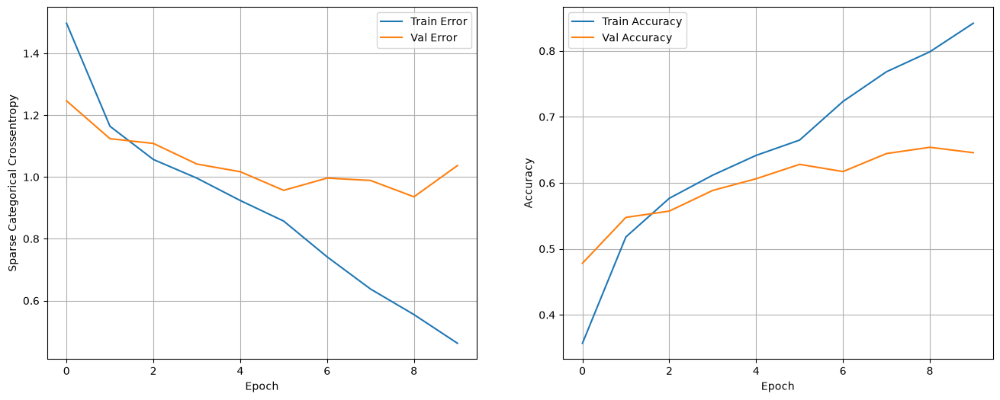

In [ ]:
### vamos a probar incrementando tanto el numero de filtros como el numero de kernel:
inputs = tf.keras.Input(shape=image_size + (3, ), name='input')
reescaling = layers.Rescaling(1. / 255)(inputs)

# Conv Layer 1
conv_1 = layers.Conv2D(filters=16, kernel_size=4, padding='valid', activation='relu',
                       name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_1')(conv_1)

# Conv Layer 2
conv_2 = layers.Conv2D(filters=16, kernel_size=4, padding='valid', activation='relu',
                       name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_2')(conv_2)


# Fully-connected
# Flattening
flat = layers.Flatten(name='flatten')(pool_2)
dense = layers.Dense(64, activation='relu', name='dense')(flat)
outputs = layers.Dense(5, activation='softmax', name='output')(dense)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_example')

print(model.summary())

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

es_callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, verbose=1)

epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback]
)
show_loss_accuracy_evolution(history)
# con esto cemos que parece que tarda mas pero q va incluso mejor pero parece q sobre todo mejora en el train.

Model: "cnn_example"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 96, 96, 4)      │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 30, 30, 4)      │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 15, 15, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        57,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,249 (227.54 KB)

 Trainable params: 58,249 (227.54 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.3597 - loss: 1.4659 - val_accuracy: 0.4959 - val_loss: 1.3094
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.4765 - loss: 1.2964 - val_accuracy: 0.5082 - val_loss: 1.2361
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.5290 - loss: 1.1879 - val_accuracy: 0.5313 - val_loss: 1.1640
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.5678 - loss: 1.0941 - val_accuracy: 0.5695 - val_loss: 1.0689
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.5923 - loss: 1.0455 - val_accuracy: 0.5436 - val_loss: 1.1168
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.6049 - loss: 1.0218 - val_accuracy: 0.5886 - val_loss: 1.0492
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.6097 - loss: 0.9876 - val_accuracy: 0.5926 - val_loss: 1.0249
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.6369 - loss: 0.9428 - val_accuracy: 0.5518 - val_loss: 1.

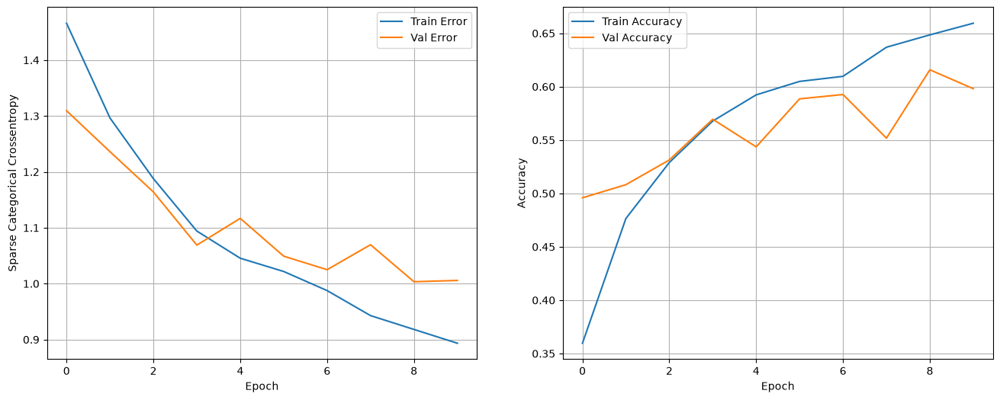

In [ ]:
## vamos a variar el pool size a ve que pasa pero solo en la primera capa

inputs = tf.keras.Input(shape=image_size + (3, ), name='input')
reescaling = layers.Rescaling(1. / 255)(inputs)

# Conv Layer 1
conv_1 = layers.Conv2D(filters=4, kernel_size=3, padding='same', activation='relu',
                       name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(3, 3), name='pool_1')(conv_1)

# Conv Layer 2
conv_2 = layers.Conv2D(4, 3, padding='valid', activation='relu',
                       name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_2')(conv_2)

# Fully-connected
# Flattening
flat = layers.Flatten(name='flatten')(pool_2)
dense = layers.Dense(64, activation='relu', name='dense')(flat)
outputs = layers.Dense(5, activation='softmax', name='output')(dense)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_example')

print(model.summary())

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

es_callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, verbose=1)

epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback]
)
show_loss_accuracy_evolution(history)

# parece que mejora bastante el modelo para conseguir un modelo con mayor accuracy vamos a aplicar ambos solucione que vimos anteriormente.majorar el spool y aumentar los filtros

Model: "cnn_example"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 96, 96, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 24, 24, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,101 (359.77 KB)

 Trainable params: 92,101 (359.77 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 195ms/step - accuracy: 0.3886 - loss: 1.4026 - val_accuracy: 0.4782 - val_loss: 1.2087
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.5552 - loss: 1.0991 - val_accuracy: 0.5926 - val_loss: 1.0228
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.6178 - loss: 0.9762 - val_accuracy: 0.6294 - val_loss: 0.9525
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step - accuracy: 0.6529 - loss: 0.9044 - val_accuracy: 0.6185 - val_loss: 0.9819
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step - accuracy: 0.6642 - loss: 0.8375 - val_accuracy: 0.6512 - val_loss: 0.9239
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.6849 - loss: 0.7991 - val_accuracy: 0.6771 - val_loss: 0.9209
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step - accuracy: 0.6962 - loss: 0.7907 - val_accuracy: 0.6812 - val_loss: 0.8683
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.7302 - loss: 0.7103 - val_accuracy: 0.6689 - val

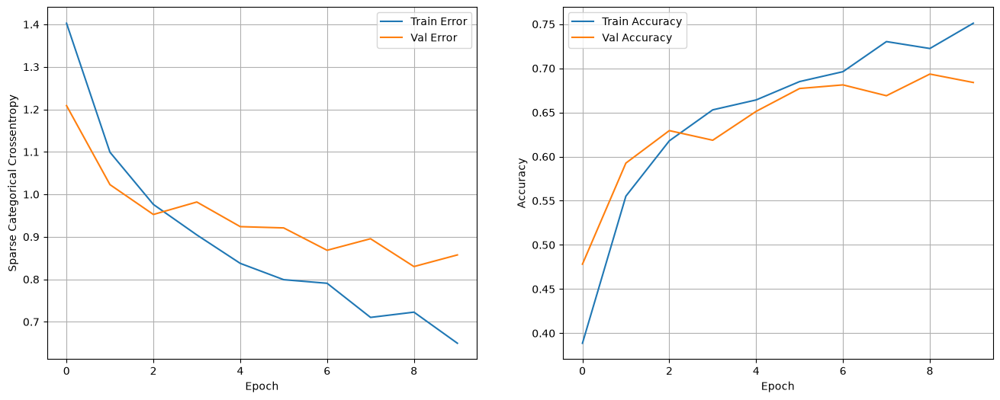

In [ ]:
## vamos a variar el pool size a ve que pasa pero solo en la primera capa

inputs = tf.keras.Input(shape=image_size + (3, ), name='input')
reescaling = layers.Rescaling(1. / 255)(inputs)

# Conv Layer 1
conv_1 = layers.Conv2D(filters=32, kernel_size=4, padding='same', activation='relu',
                       name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(4, 4), name='pool_1')(conv_1)

# Conv Layer 2
conv_2 = layers.Conv2D(32, 4, padding='same', activation='relu',
                       name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(pool_size=(4, 4), name='pool_2')(conv_2)

# Fully-connected
# Flattening
flat = layers.Flatten(name='flatten')(pool_2)
dense = layers.Dense(64, activation='relu', name='dense')(flat)
outputs = layers.Dense(5, activation='softmax', name='output')(dense)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_example')

print(model.summary())

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

es_callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, verbose=1)

epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback]
)
show_loss_accuracy_evolution(history)

# parece que mejora bastante el modelo para conseguir un modelo con mayor accuracy vamos a aplicar ambos solucione que vimos anteriormente.majorar el spool y aumentar los filtros
# poneindo uina capa mas podria funcionar incluso mejor

In [44]:
## data augmentation

data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.25),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(factor=0.2)
  ]
)

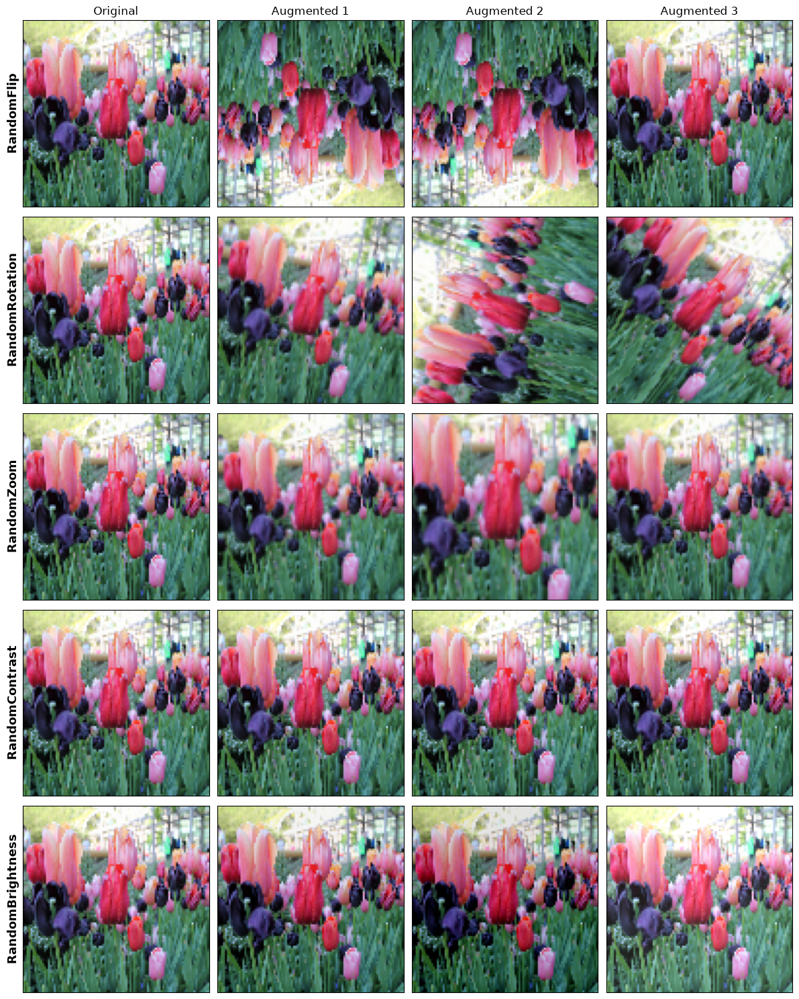

In [ ]:
# Visualize each augmentation individually
individual_augmentations = {
    'RandomFlip': layers.RandomFlip("horizontal_and_vertical"),
    'RandomRotation': layers.RandomRotation(0.25),
    'RandomZoom': layers.RandomZoom(0.25),
    'RandomContrast': layers.RandomContrast(0.1),
    'RandomBrightness': layers.RandomBrightness(factor=0.2),
}

# Get a sample image
for images, _ in train_ds.take(1):
    sample_image = images[0]
    break

n_aug = len(individual_augmentations)
fig, axes = plt.subplots(n_aug, 4, figsize=(12, 3 * n_aug))

for row, (name, aug_layer) in enumerate(individual_augmentations.items()):
    for col in range(4):
        if col == 0:
            axes[row, col].imshow(sample_image.numpy().astype("uint8"))
            axes[row, col].set_title(f'Original' if row == 0 else '')
        else:
            augmented = aug_layer(tf.expand_dims(sample_image, 0), training=True)
            axes[row, col].imshow(augmented[0].numpy().astype("uint8"))
            if row == 0:
                axes[row, col].set_title(f'Augmented {col}')
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    # Add transformation name on the left
    axes[row, 0].set_ylabel(name, fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# con esto vemos que le hace de todo a la imagen. vamos a ver si mejora el modelo con este data augmentation como si fuese una capa mas. pero esto lo veremos tras realizar mas tipos de augmentation

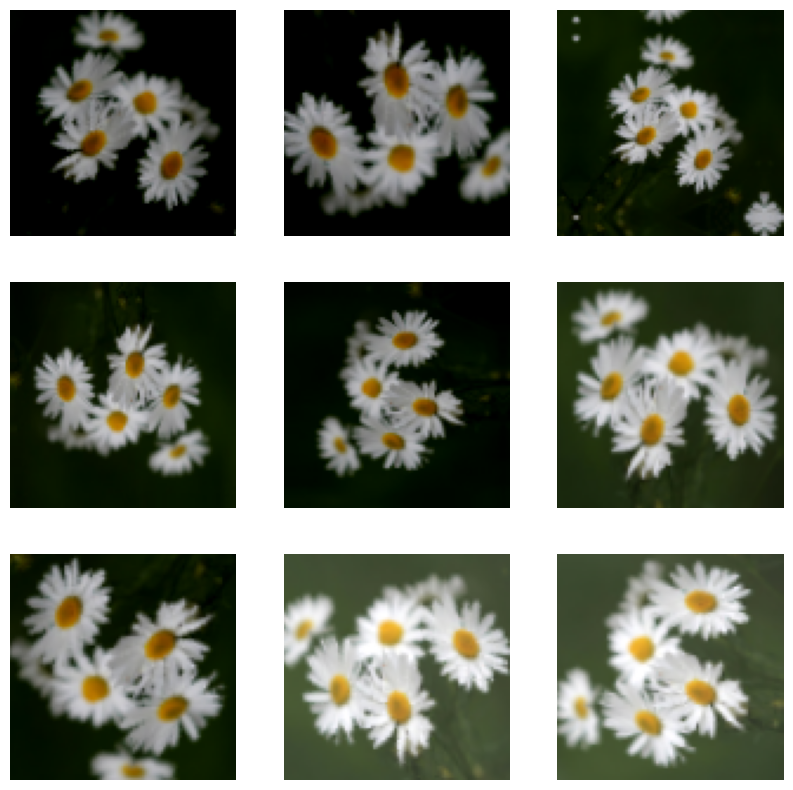

In [46]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images, training=True)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_images[0].numpy().astype("uint8"))
        plt.axis("off")

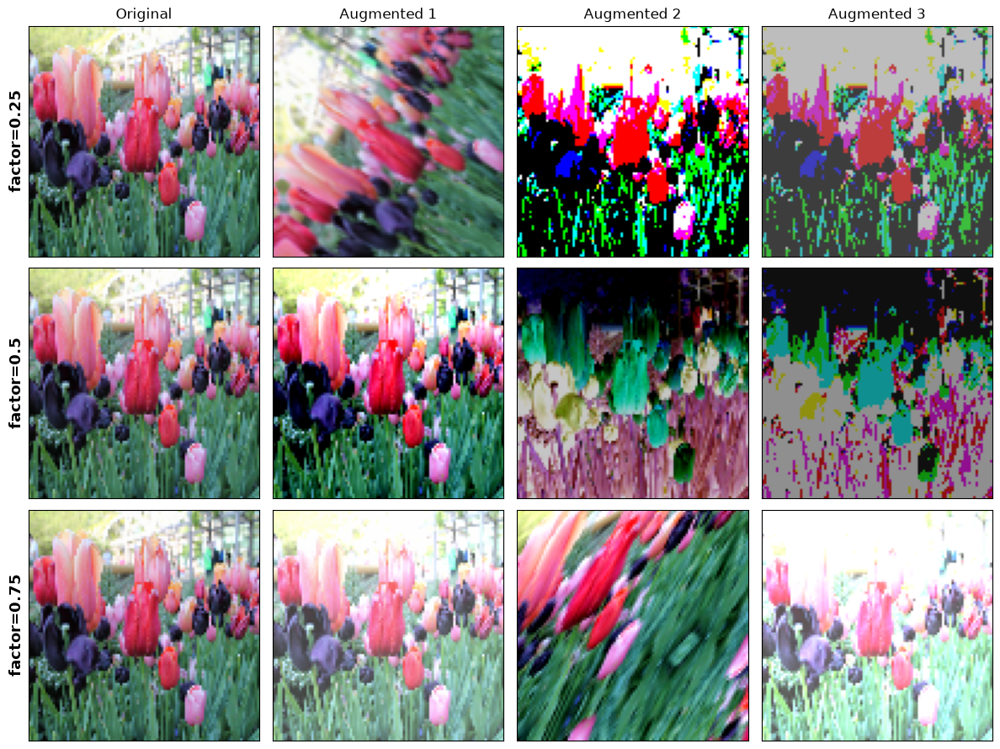

In [47]:
rand_augment = keras.layers.RandAugment(value_range=(0, 255), num_ops=2, factor=0.5)

# Compare different factor values
factors = [0.25, 0.5, 0.75]
fig, axes = plt.subplots(len(factors), 4, figsize=(12, 3 * len(factors)))

for row, factor in enumerate(factors):
    ra = keras.layers.RandAugment(value_range=(0, 255), num_ops=2, factor=factor)
    for col in range(4):
        if col == 0:
            axes[row, col].imshow(sample_image.numpy().astype("uint8"))
            if row == 0:
                axes[row, col].set_title('Original')
        else:
            augmented = ra(tf.expand_dims(sample_image, 0), training=True)
            axes[row, col].imshow(augmented[0].numpy().astype("uint8"))
            if row == 0:
                axes[row, col].set_title(f'Augmented {col}')
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(f'factor={factor}', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
inputs = tf.keras.Input(shape=image_size + (3, ), name='input')
data_aug = data_augmentation(inputs) # con esto creamos la capa mas para poder ver como mejora el modelo
reescaling = layers.Rescaling(1. / 255)(data_aug)

# Conv Layer 1
conv_1 = layers.Conv2D(8, 3, padding='valid', activation='relu',
                       name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(2, 2), name='pool_1')(conv_1)

# Conv Layer 2
conv_2 = layers.Conv2D(8, 3, padding='valid', activation='relu',
                       name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(name='pool_2')(conv_2)

# Conv Layer 3
conv_3 = layers.Conv2D(8,
                       3,
                       padding='valid',
                       activation='relu',
                       name='conv_3')(pool_2)
pool_3 = layers.MaxPooling2D(name='pool_3')(conv_3)

# Fully-connected
flat = layers.Flatten(name='flatten')(pool_3)
dense = layers.Dense(64, activation='relu', name='dense')(flat)
outputs = layers.Dense(5, activation='softmax', name='output')(dense)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_example')

Epoch 1/10


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 171ms/step - accuracy: 0.2984 - loss: 1.5488 - val_accuracy: 0.4673 - val_loss: 1.3536
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 136ms/step - accuracy: 0.4588 - loss: 1.2745 - val_accuracy: 0.5014 - val_loss: 1.1642
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 197ms/step - accuracy: 0.4993 - loss: 1.1794 - val_accuracy: 0.5368 - val_loss: 1.1466
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 214ms/step - accuracy: 0.5388 - loss: 1.1295 - val_accuracy: 0.5327 - val_loss: 1.1508
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 209ms/step - accuracy: 0.5579 - loss: 1.0885 - val_accuracy: 0.5627 - val_loss: 1.0914
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 162ms/step - accuracy: 0.5702 - loss: 1.0566 - val_accuracy: 0.5668 - val_loss: 1.0431
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 123ms/step - accuracy: 0.5773 - loss: 1.0387 - val_accuracy: 0.6131 - val_loss: 0.9899
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.5954 - loss: 1.0041 - val_accuracy: 0.5804 - v

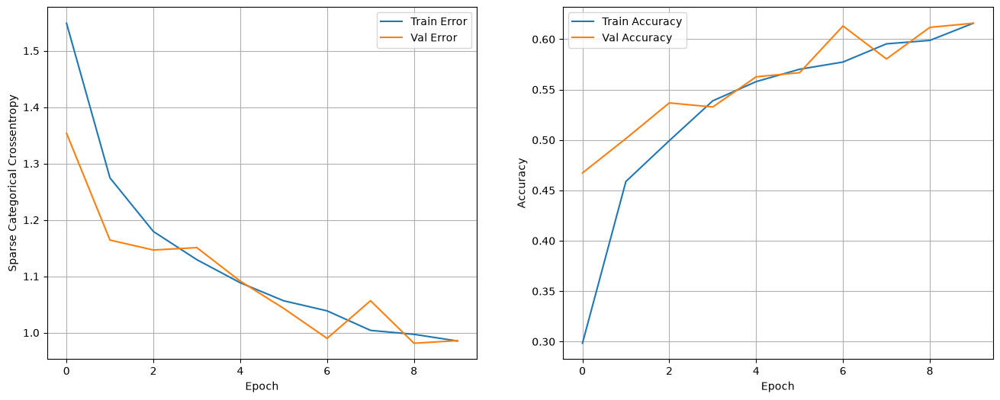

In [49]:
es_callback = keras.callbacks.EarlyStopping(
    monitor='val_loss',  # can be 'val_accuracy'
    patience=10,  # if during 10 epochs there is no improvement in `val_loss`, the execution will stop
    verbose=1)

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback]
)
show_loss_accuracy_evolution(history)

## con este data augmentation vemos que mejora bastante el modelo ya que al final hace que se vea la imagen con muchos tipos disitntos de formas (colores, lados,..)

In [ ]:
## ahora vemos el transfer learning

pretrained_model = tf.keras.applications.MobileNetV2(input_shape=image_size+(3,), include_top=False) # modelo que se han currado mucho. le ponermos a false q no nos incluya la ultima capa ya que nuestra ultima capa deberia de tener solo 5 nodos (predecir las flores)
pretrained_model.trainable = False
pretrained_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_96"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input # vamos a poner ub modelo encima de este ya entrenado y fuerte

In [52]:
inputs = tf.keras.Input(shape=image_size + (3, ), name='input')

# pre-trained model
x = preprocess_input(inputs)
x = pretrained_model(x)

# classifier
flat = tf.keras.layers.Flatten()(x)
flat = tf.keras.layers.Dropout(0.5)(flat)
outputs = tf.keras.layers.Dense(5, activation='softmax')(flat)

model_tl = tf.keras.Model(inputs, outputs)
model_tl.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        57,605 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,315,589 (8.83 MB)

 Trainable params: 57,605 (225.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [53]:
model_tl.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [54]:
es_callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, verbose=1)

epochs = 5
history = model_tl.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs,
  callbacks=[es_callback]
)

Epoch 1/5


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 411ms/step - accuracy: 0.7360 - loss: 1.0262 - val_accuracy: 0.8624 - val_loss: 0.5621
Epoch 2/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 13s 286ms/step - accuracy: 0.8873 - loss: 0.3668 - val_accuracy: 0.8529 - val_loss: 0.5739
Epoch 3/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 266ms/step - accuracy: 0.9234 - loss: 0.2237 - val_accuracy: 0.8597 - val_loss: 0.6298
Epoch 4/5
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 266ms/step - accuracy: 0.9544 - loss: 0.1389 - val_accuracy: 0.8719 - val_loss: 0.6279
Epoch 4: early stopping


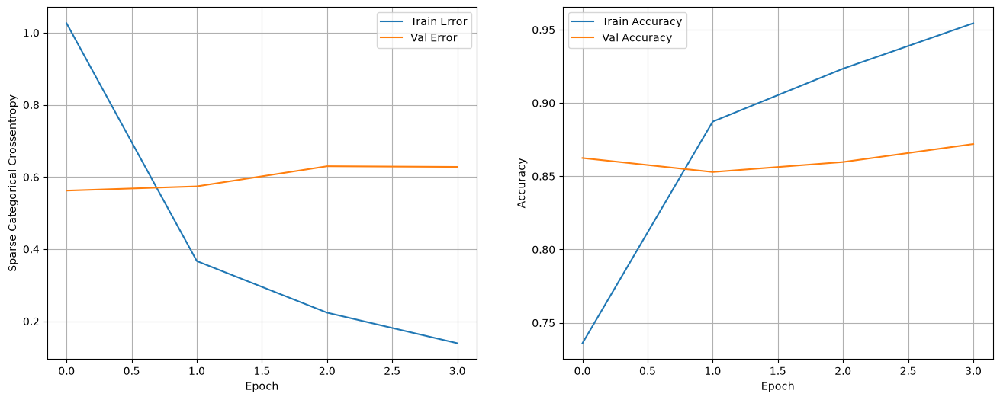

In [ ]:
show_loss_accuracy_evolution(history) # vemos que el modelo va como un tiro vmaos

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step


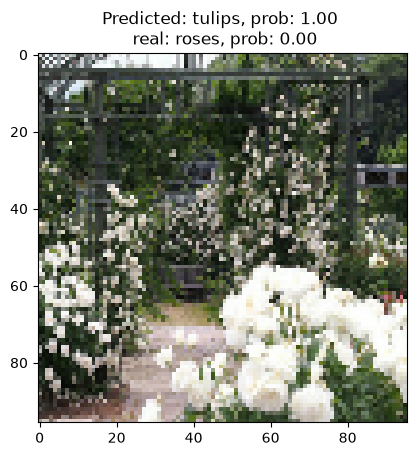

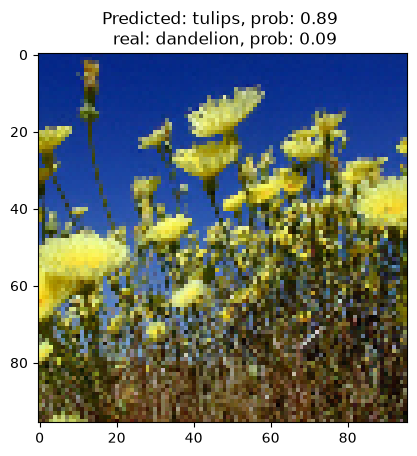

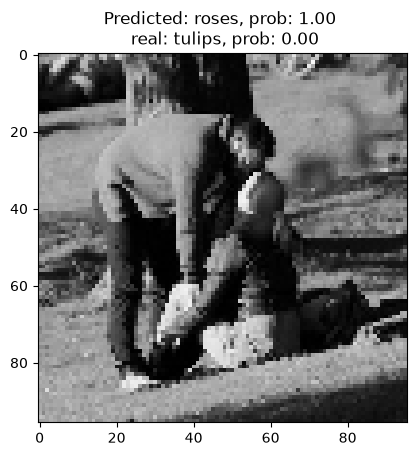

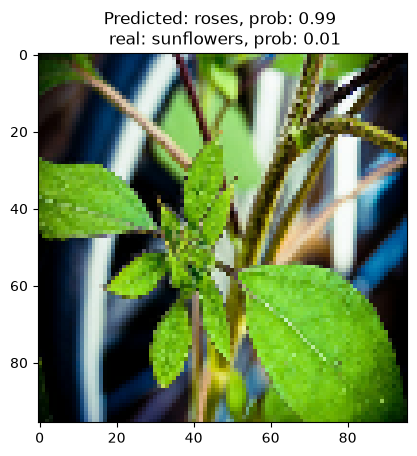

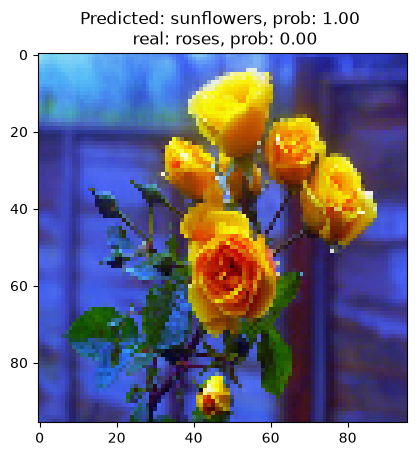


--- Extreme errors (lowest probability for the real class) ---
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


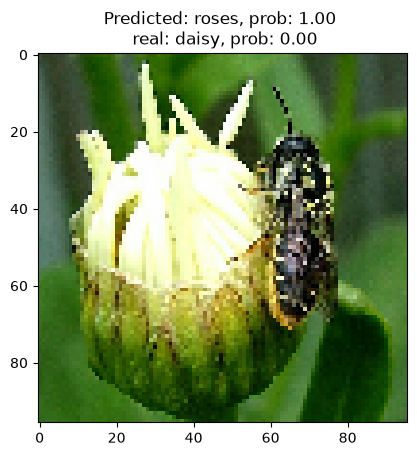

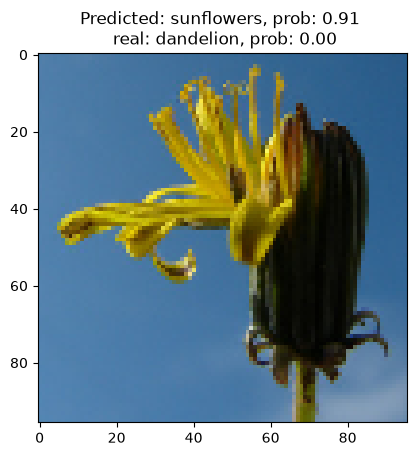

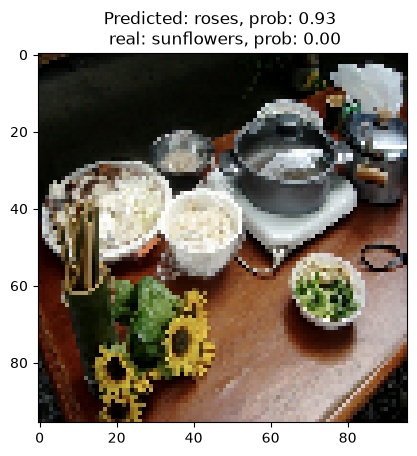

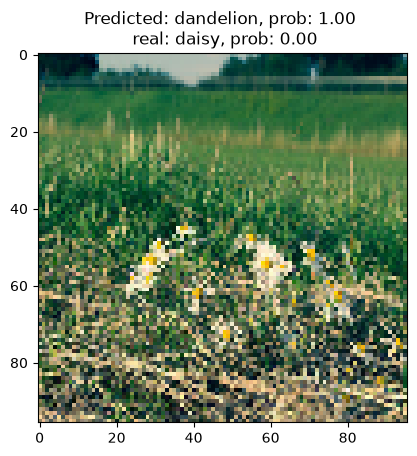

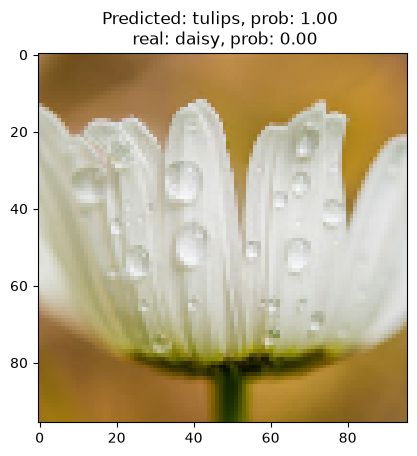

In [56]:
show_errors(val_ds, model_tl, class_names_list, n_images=5)
print('\n--- Extreme errors (lowest probability for the real class) ---')
show_extreme_errors(val_ds, model_tl, class_names_list, n_images=5)

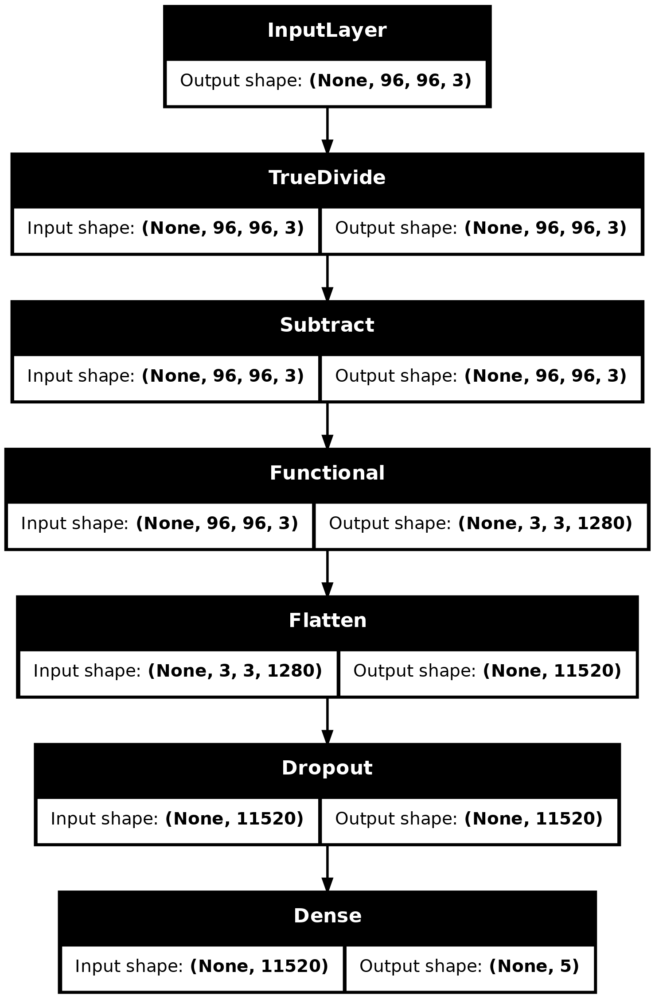

In [57]:
from tensorflow.keras.utils import plot_model
plot_model(model_tl, show_shapes=True)

In [58]:
# vamos a añadir unas capas de convolucion y el modelo preentrenado:
inputs = tf.keras.Input(shape=image_size+(3, ), name='input')

#data_aug = data_augmentation(inputs)
reescaling = preprocess_input(inputs)

# Conv Layer 1
conv_1 = layers.Conv2D(16, 3, padding='valid',
                       activation='relu', name='conv_1')(reescaling)
pool_1 = layers.MaxPooling2D(pool_size=(
    2, 2),  name='pool_1')(conv_1)
pool_1 = layers.Dropout(0.4)(pool_1)

# Conv Layer 2
conv_2 = layers.Conv2D(16, 3, padding='valid',
                       activation='relu', name='conv_2')(pool_1)
pool_2 = layers.MaxPooling2D(name='pool_2')(conv_2)
pool_2 = layers.Dropout(0.4)(pool_2)

# Conv Layer 3
conv_3 = layers.Conv2D(16, 3, padding='valid',
                       activation='relu', name='conv_3')(pool_2)
pool_3 = layers.MaxPooling2D(name='pool_3')(conv_3)
pool_3 = layers.Dropout(0.4)(pool_3)

# Fully-connected
x1 = layers.Flatten(name='flatten')(pool_3)

x2 = pretrained_model(reescaling, training=False)
x2 = tf.keras.layers.Flatten()(x2)

x = tf.keras.layers.Concatenate()([x1, x2])
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation='relu', name='dense')(x)
outputs = tf.keras.layers.Dense(5, activation='softmax')(x)
model_tl = keras.Model(inputs, outputs)

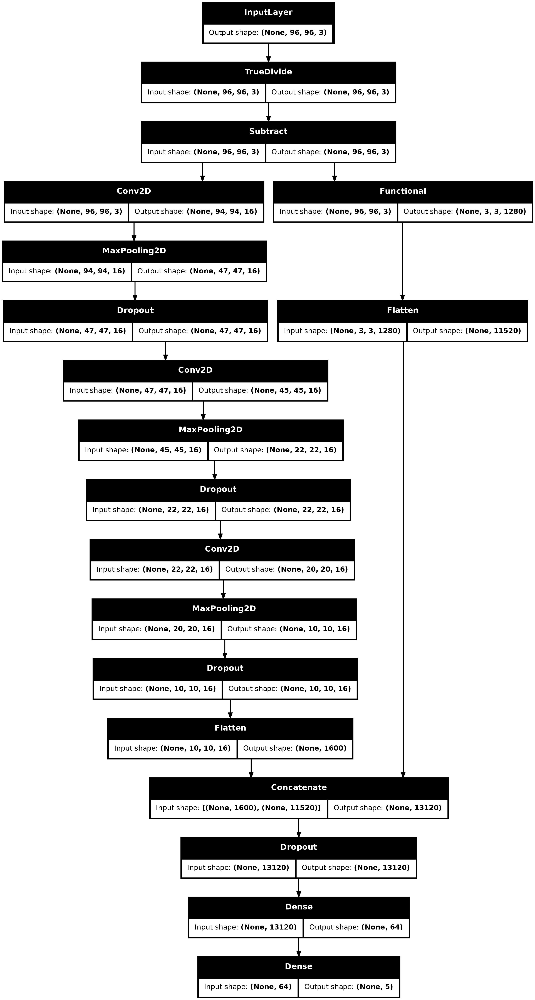

In [59]:
from tensorflow.keras.utils import plot_model
plot_model(model_tl, show_shapes=True)

In [60]:
model_tl.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
epochs = 15
history = model_tl.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Epoch 1/15


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 30s 551ms/step - accuracy: 0.7803 - loss: 0.6706 - val_accuracy: 0.8447 - val_loss: 0.4576
Epoch 2/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 20s 447ms/step - accuracy: 0.9493 - loss: 0.1481 - val_accuracy: 0.8733 - val_loss: 0.4613
Epoch 3/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 20s 429ms/step - accuracy: 0.9928 - loss: 0.0481 - val_accuracy: 0.8665 - val_loss: 0.5137
Epoch 4/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 365ms/step - accuracy: 0.9969 - loss: 0.0224 - val_accuracy: 0.8583 - val_loss: 0.5092
Epoch 5/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 317ms/step - accuracy: 0.9993 - loss: 0.0113 - val_accuracy: 0.8678 - val_loss: 0.5299
Epoch 6/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 321ms/step - accuracy: 0.9997 - loss: 0.0065 - val_accuracy: 0.8665 - val_loss: 0.5554
Epoch 7/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 314ms/step - accuracy: 0.9993 - loss: 0.0092 - val_accuracy: 0.8692 - val_loss: 0.5494
Epoch 8/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 325ms/step - accuracy: 0.9997 - loss: 0.0052 - val_accuracy: 0.870

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step


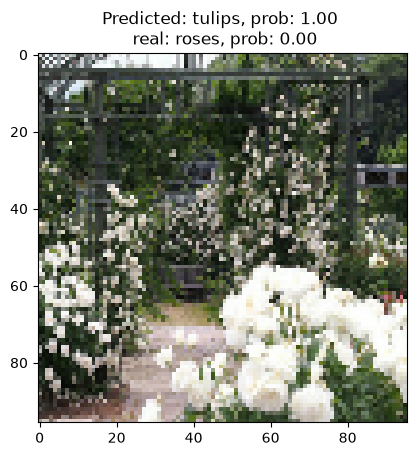

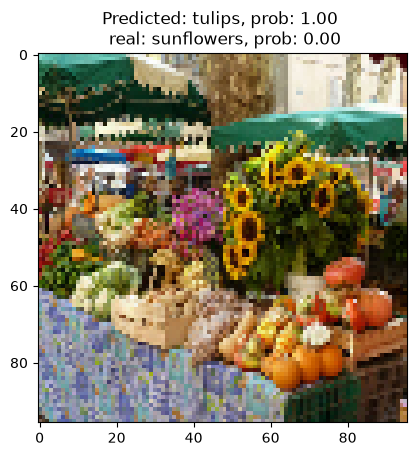

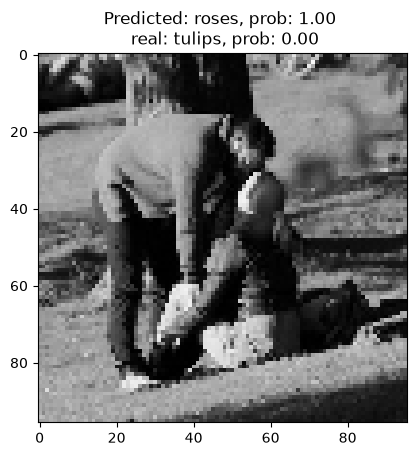

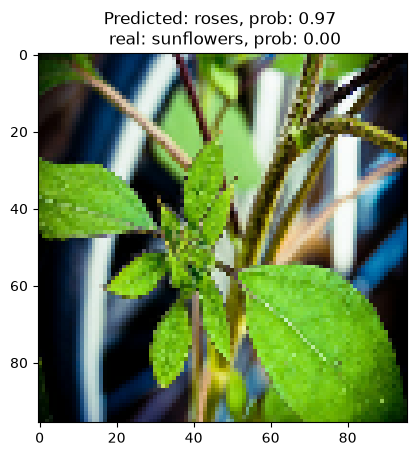

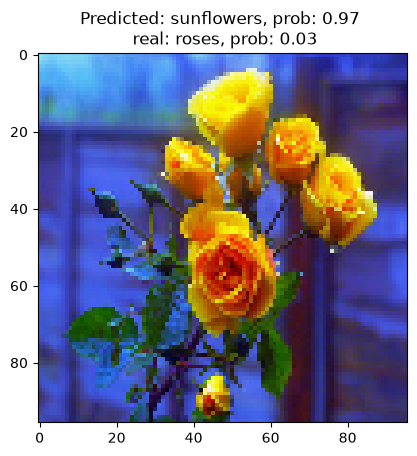

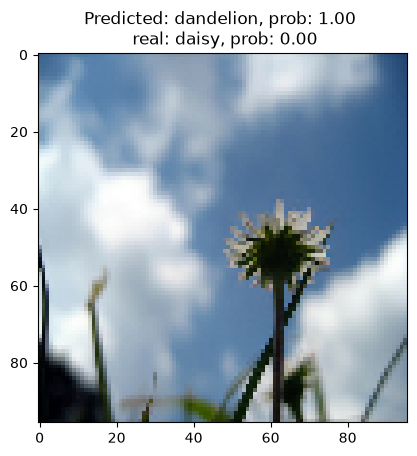

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step


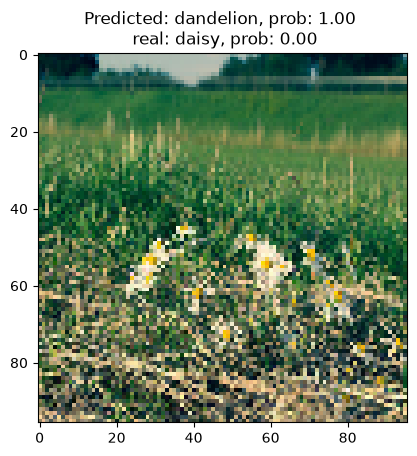

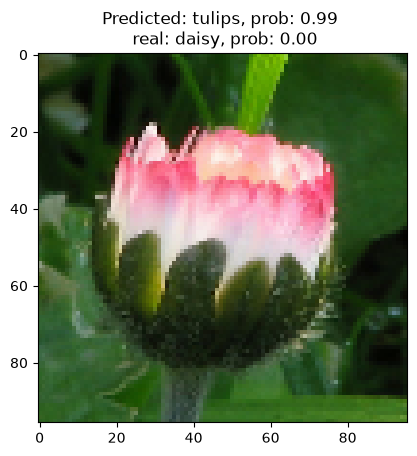

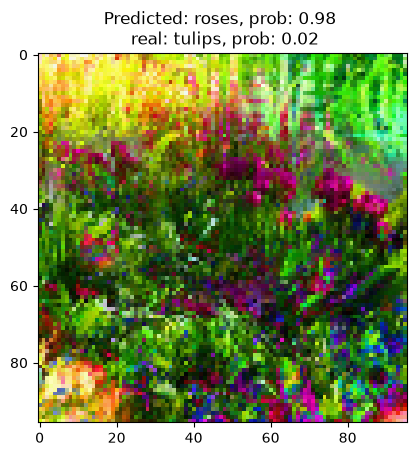

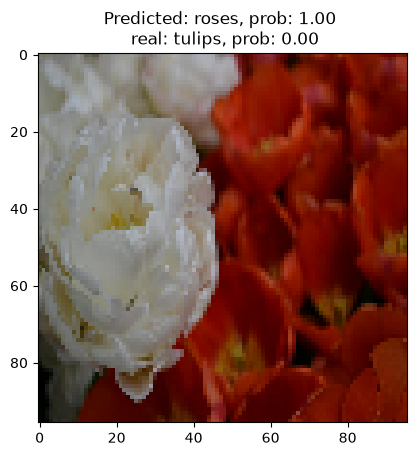

In [61]:
show_errors(val_ds, model_tl, class_names_list, n_images=10)

In [ ]:
## fine - tuning -> esto sirve para medir mejor los pesos. esto  a no ser que tengamos muchos pesos no funciona bien y ademas tarda bastante
pretrained_model_ft = tf.keras.applications.MobileNetV2(input_shape=image_size+(3,), include_top=False)

inputs = tf.keras.Input(shape=image_size + (3,), name='input')
x = data_augmentation(inputs)
x = preprocess_input(x)
x = pretrained_model_ft(x)
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dropout(0.5)(x)
outputs = tf.keras.layers.Dense(5, activation='softmax')(x)

model_tl = tf.keras.Model(inputs, outputs)
model_tl.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │        57,605 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,315,589 (8.83 MB)

 Trainable params: 2,281,477 (8.70 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [63]:
es_callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, verbose=1)

model_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

epochs = 20
history = model_tl.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback]
)
show_loss_accuracy_evolution(history)

Epoch 1/20
 1/46 ━━━━━━━━━━━━━━━━━━━━ 24:04 32s/step - accuracy: 0.1562 - loss: 3.4726

W0000 00:00:1792317554.733334   36521 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1792317522636940775 in buffer 'PrefetchDataset/_26' sat unconsumed for 32.0964 seconds!


 7/46 ━━━━━━━━━━━━━━━━━━━━ 1:13 2s/step - accuracy: 0.1875 - loss: 3.1663

KeyboardInterrupt: 